<a href="https://colab.research.google.com/github/nicolehernandez029/RedConecta/blob/main/RedConecta_Nicole_Hernandez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Latencia promedio: 64.86149999999999
Resolución promedio: 25.3295
Correlación entre tráfico y latencia: -0.07679204435530577
                       registros  cumplimiento_sla  latencia_media  \
region tipo_servicio                                                 
Centro Empresas               24         45.833333       69.416667   
       Internet Hogar         27         37.037037       66.948148   
       Móvil                  17         52.941176       67.917647   
Norte  Empresas               18         38.888889       68.594444   
       Internet Hogar         30         43.333333       59.560000   
       Móvil                  17         52.941176       69.435294   
Sur    Empresas               22         59.090909       69.413636   
       Internet Hogar         22         63.636364       62.922727   
       Móvil                  23         43.478261       53.513043   

                       resolucion_media  tickets  
region tipo_servicio                              
Ce

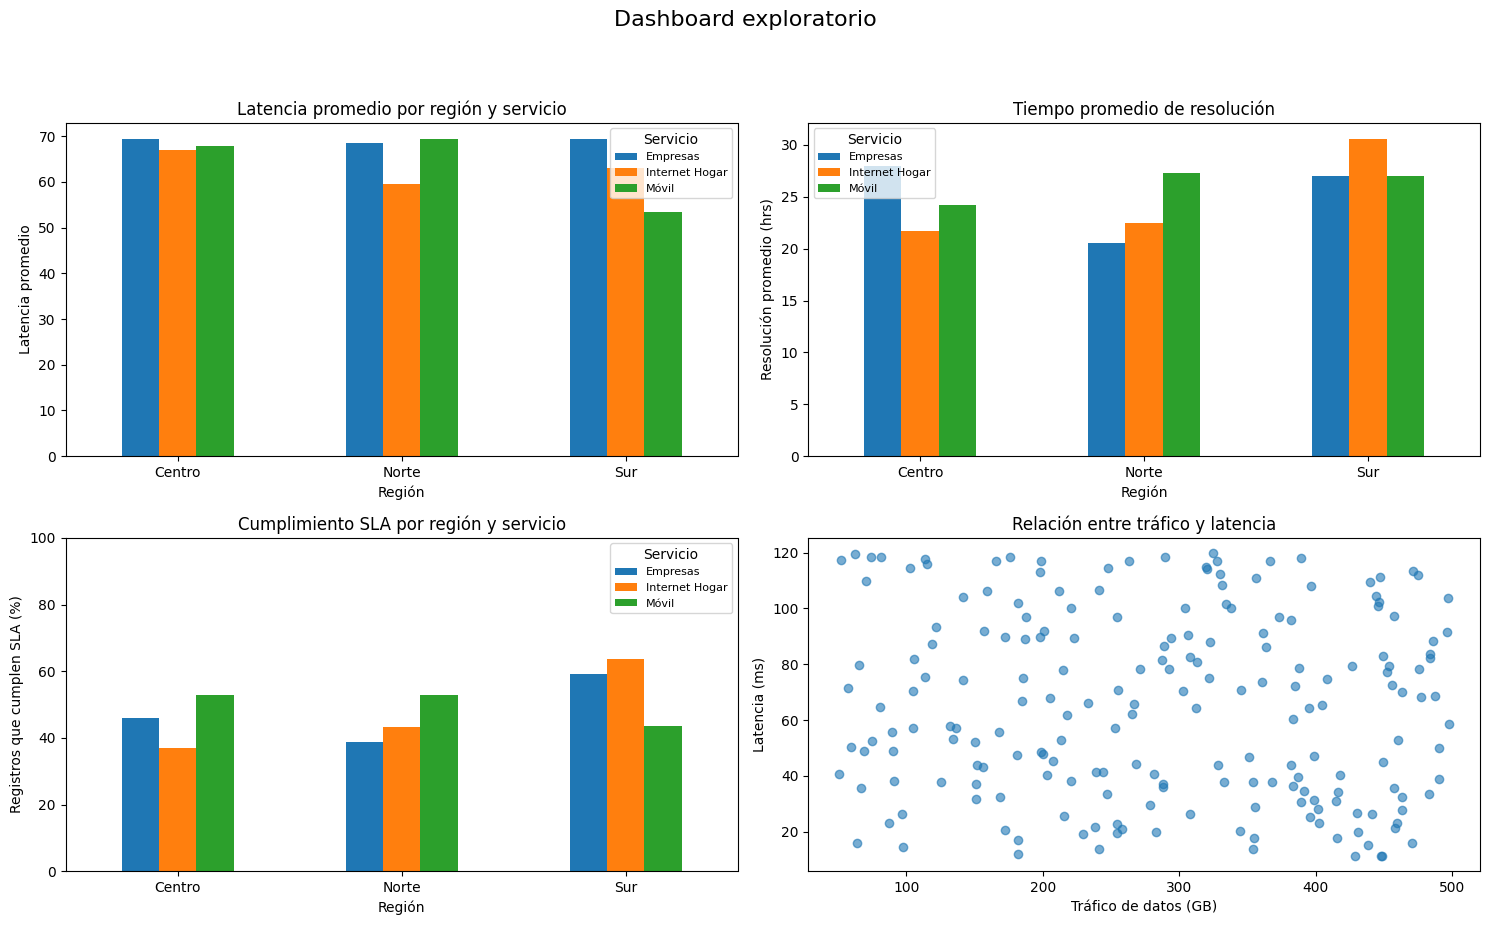

In [ ]:
#Importando pandas
import pandas as pd
import matplotlib.pyplot as plt

#Llamar a excel y a la hoja donde esta la informacion
df = pd.read_excel( "/content/RedConecta/dataset_set_D_telecomunicaciones.xlsx",sheet_name="Sheet1")

# Importar las funciones del otro archivo,respuesta 4
from funciones_analisis import (
    calcular_promedio,
    calcular_correlacion,
    guardar_resultados
)

# Usar la misma función para calcular dos promedios.
latencia = calcular_promedio(df["latencia_ms"])
resolucion = calcular_promedio(df["tiempo_resolucion_hr"])

# Calcular la correlación entre tráfico y latencia.
correlacion = calcular_correlacion(
    df["trafico_datos_gb"],
    df["latencia_ms"]
)

# Mostrar los resultados.
print("Latencia promedio:", latencia)
print("Resolución promedio:", resolucion)
print("Correlación entre tráfico y latencia:", correlacion)

# Guardar los resultados con nombres para identificarlos.
resultados = {
    "latencia_promedio": latencia,
    "resolucion_promedio": resolucion,
    "correlacion": correlacion
}

guardar_resultados(resultados)

#convertir la columna fecha_regristro a tipo fecha en formato pandas
df["fecha_registro"] = pd.to_datetime(df["fecha_registro"])
#crea una columna que indica si el SLA se cumple o no, usando la columna cumplimiento_sla
df["sla_cumple"] = df["cumplimiento_sla"].eq("Cumple")
#agrupar los datos por region y tipo de servicio
resumen = df.groupby(["region", "tipo_servicio"]).agg(
    #tamaño del grupo
    registros=("sla_cumple", "size"),
    #promedio de cumplimiento de SLA
    cumplimiento_sla=("sla_cumple", "mean"),
    #promedio latencia media
    latencia_media=("latencia_ms", "mean"),
    #promedio resolución media
    resolucion_media=("tiempo_resolucion_hr", "mean"),
    #suma de tickets de soporte
    tickets=("tickets_soporte", "sum")
)
#Convertir el promedio de cumplimiento de SLA a porcentaje
resumen["cumplimiento_sla"] *= 100
#Exportar el resumen a un archivo CSV
resumen.to_csv("resumen_servicio.csv", encoding="utf-8-sig")
#Mostrar el resumen
print(resumen)

# Crear cuadro de 4 gráficos para el dashboard.
fig, ejes = plt.subplots(2, 2, figsize=(15, 10))

# Agregar el título al dashboard.
fig.suptitle("Dashboard exploratorio",fontsize=16)

# Grafico 1: Latencia promedio.
# unstack organiza los servicios como columnas para compararlos.
resumen["latencia_media"].unstack().plot(
    kind="bar",
    ax=ejes[0, 0]
)
ejes[0, 0].set_title("Latencia promedio por región y servicio")
ejes[0, 0].set_xlabel("Región")
ejes[0, 0].set_ylabel("Latencia promedio")
ejes[0, 0].tick_params(axis="x", rotation=0)
ejes[0, 0].legend(title="Servicio", fontsize=8)

# Grafico 2: Tiempo promedio de resolución.
resumen["resolucion_media"].unstack().plot(
    kind="bar",
    ax=ejes[0, 1]
)
ejes[0, 1].set_title("Tiempo promedio de resolución")
ejes[0, 1].set_xlabel("Región")
ejes[0, 1].set_ylabel("Resolución promedio (hrs)")
ejes[0, 1].tick_params(axis="x", rotation=0)
ejes[0, 1].legend(title="Servicio", fontsize=8)

# Grafico3: Porcentaje de registros que cumplen SLA.
resumen["cumplimiento_sla"].unstack().plot(
    kind="bar",
    ax=ejes[1, 0]
)
ejes[1, 0].set_title("Cumplimiento SLA por región y servicio")
ejes[1, 0].set_xlabel("Región")
ejes[1, 0].set_ylabel("Registros que cumplen SLA (%)")
ejes[1, 0].set_ylim(0, 100)
ejes[1, 0].tick_params(axis="x", rotation=0)
ejes[1, 0].legend(title="Servicio", fontsize=8)

# Grafico 4: Relacion entre trafico y latencia.
ejes[1, 1].scatter(
    df["trafico_datos_gb"],
    df["latencia_ms"],
    alpha=0.6
)
ejes[1, 1].set_title("Relación entre tráfico y latencia")
ejes[1, 1].set_xlabel("Tráfico de datos (GB)")
ejes[1, 1].set_ylabel("Latencia (ms)")

# Ajustar los espacios para evitar superposición de textos.
plt.tight_layout(rect=[0, 0.06, 1, 0.94])

# Guardar el dashboard como imagen para incorporarlo al informe.
plt.savefig("dashboard_servicio.png", dpi=300)
# Mostrar el dashboard.
plt.show()